# Train on Jonas voice and test on Camille voice

## Imports 

In [64]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/src")))

In [65]:
import tensorflow as tf
import numpy as np
import os, glob
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from preprocessing import AudioPipeline
from preprocessing.dataset_pipeline import load_and_preprocess, make_dataset
from preprocessing.transfer_model import build_transfer_model
from sklearn.metrics import classification_report, confusion_matrix

## Config

In [66]:
DATA_DIR    = "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/data/Splitted data well organized"
TRAIN_SPEAKER = ["Jonas"]
TEST_SPEAKER  = ["Camille"]
CLASSES     = ["silence", "talky", "unknown"]
BATCH_SIZE  = 16      
EPOCHS   = 50       # backbone gelé
LR       = 1e-4
KERAS_PATH  = "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/src/models/miniresnetv2_s1_64x50_tl.keras"

pipeline = AudioPipeline("/home/f24achba/Documents/Edge AI/52-Hertz-KWS/configuration/config.yaml")

## Chargement des chemins + labels 

In [67]:
def load_speaker(speaker_name):
    paths, labels = [], []
    for label_idx, class_name in enumerate(CLASSES):
        wavs = glob.glob(os.path.join(DATA_DIR, speaker_name, class_name, "*.wav"))
        paths  += wavs
        labels += [label_idx] * len(wavs)
        print(f"  [{speaker_name}] {class_name:10s} → {len(wavs)} fichiers")
    return np.array(paths), np.array(labels)

train_paths, train_labels = load_speaker(TRAIN_SPEAKER[0])
test_paths,  test_labels  = load_speaker(TEST_SPEAKER[0])

  [Jonas] silence    → 64 fichiers
  [Jonas] talky      → 172 fichiers
  [Jonas] unknown    → 142 fichiers
  [Camille] silence    → 71 fichiers
  [Camille] talky      → 123 fichiers
  [Camille] unknown    → 184 fichiers


## Split sans validation set

In [68]:
#X_train, y_train = train_paths, train_labels  
#X_test,  y_test  = test_paths,  test_labels   

## Split avec validation 

In [69]:

# Val = 15% du locuteur d'entraînement seulement
X_train, X_val, y_train, y_val = train_test_split(
    train_paths, train_labels,
    test_size=0.15,
    stratify=train_labels,
    random_state=42
)
X_test, y_test = test_paths, test_labels

print(f"Train : {len(X_train)} | Val : {len(X_val)} | Test : {len(X_test)}")
print(f"→ Train/Val = {TRAIN_SPEAKER[0]} | Test = {TEST_SPEAKER[0]}")

Train : 321 | Val : 57 | Test : 378
→ Train/Val = Jonas | Test = Camille


## Class weights 

In [70]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print(f"\nClass weights : {class_weight_dict}")


Class weights : {0: 1.9814814814814814, 1: 0.7328767123287672, 2: 0.8842975206611571}


## tf.data pipeline 

In [71]:
train_ds = make_dataset(X_train, y_train, BATCH_SIZE, augment=True)
val_ds   = make_dataset(X_val,   y_val, BATCH_SIZE,  augment=False)
test_ds  = make_dataset(X_test,  y_test, BATCH_SIZE, augment=False)

## model 

In [ ]:

model = build_transfer_model(KERAS_PATH, num_classes=3)
model.compile(
    optimizer=tf.keras.optimizers.Adam(LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


Model: "miniresnet_kws"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_4             │ (None, 64, 50, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 70, 56, 1) │          0 │ input_4[0][0]     │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 32, 25,    │      3,200 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 34, 27,    │          0 │ conv1_conv[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 16, 13,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 16, 13,    │        256 │ pool1_pool[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 16, 13,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 16, 13,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 16, 13,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 16, 13,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 18, 15,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 16, 13,    │      4,160 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 16, 13,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 16, 13,    │          0 │ conv2_block1_0_c… │
│ (Add)               │ 64)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_preac… │ (None, 16, 13,    │        256 │ conv2_block1_out… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_preac… │ (None, 16, 13,    │          0 │ conv2_block2_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 16, 13,    │      4,096 │ conv2_block2_pre

 Total params: 101,315 (395.76 KB)

 Trainable params: 10,755 (42.01 KB)

 Non-trainable params: 90,560 (353.75 KB)

## Callbacks avec validation set

In [ ]:

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_model_resnet_v1s2_test_data_leak_check_avec_val.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15, #ete 8                  # généreux : courbes bruitées avec peu de data
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.TensorBoard(log_dir="./logs")
]


## Callbacks sans validation set

In [74]:
""" 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_model_resnet_v2s1_speaker_data_leak_check_pas_val.keras",
        monitor="accuracy",          
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="loss",              
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.TensorBoard(log_dir="./logs")
]
"""

' \ncallbacks = [\n    tf.keras.callbacks.ModelCheckpoint(\n        "best_model_resnet_v2s1_speaker_data_leak_check_pas_val.keras",\n        monitor="accuracy",          \n        save_best_only=True,\n        verbose=1\n    ),\n    tf.keras.callbacks.ReduceLROnPlateau(\n        monitor="loss",              \n        factor=0.5,\n        patience=4,\n        min_lr=1e-6,\n        verbose=1\n    ),\n    tf.keras.callbacks.TensorBoard(log_dir="./logs")\n]\n'

## Training without validation set

In [75]:
print("\n Feature extraction (backbone gelé)")

history = model.fit(
    train_ds,
    validation_data=val_ds, 
    epochs=EPOCHS,
    callbacks=callbacks,  #callbacks,
    class_weight=class_weight_dict   # compense le déséquilibre
)


 Feature extraction (backbone gelé)
Epoch 1/50
16/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1883 - loss: 1.0950
Epoch 1: val_accuracy improved from None to 0.17544, saving model to best_model_resnet_v1s2_test_data_leak_check_avec_val.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.2181 - loss: 1.1096 - val_accuracy: 0.1754 - val_loss: 1.1119 - learning_rate: 1.0000e-04
Epoch 2/50
18/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2371 - loss: 1.0572   
Epoch 2: val_accuracy did not improve from 0.17544
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2461 - loss: 1.1017 - val_accuracy: 0.1754 - val_loss: 1.1129 - learning_rate: 1.0000e-04
Epoch 3/50
18/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2537 - loss: 1.0976   
Epoch 3: val_accuracy did not improve from 0.17544
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.2835 - loss: 1.0960 - val_accuracy: 0.1754 - val_loss: 1.1081 - learning_rate: 1.0000e-04
Epoch 4/50
16/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms

## Best model sans validation

In [76]:
#model = tf.keras.models.load_model("best_model_resnet_v2s1_speaker_data_leak_check_pas_val.keras")  
#loss, acc = model.evaluate(test_ds, verbose=0)
#print(f"Test accuracy : {acc:.3f}")

## Best model avec validation

In [77]:
model = tf.keras.models.load_model("best_model_resnet_v1s2_test_data_leak_check_avec_val.keras")  
loss, acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy : {acc:.3f}")

Test accuracy : 0.534


## Classification report sans validation set

In [78]:

#y_pred = np.argmax(model.predict(test_ds), axis=1)
#y_true = np.concatenate([y for _, y in test_ds], axis=0)
#print(classification_report(y_true, y_pred, target_names=["talky","silence","unknown"]))

## Classification report avec validation set

In [79]:
y_pred = np.argmax(model.predict(test_ds), axis=1)
y_true = np.concatenate([y for _, y in test_ds], axis=0)
print(classification_report(y_true, y_pred, target_names=["talky","silence","unknown"]))

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step
              precision    recall  f1-score   support

       talky       0.30      0.93      0.46        71
     silence       0.77      0.28      0.41       123
     unknown       0.89      0.55      0.68       184

    accuracy                           0.53       378
   macro avg       0.65      0.59      0.51       378
weighted avg       0.74      0.53      0.55       378



24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step
              precision    recall  f1-score   support

     silence       0.30      0.93      0.46        71
       talky       0.77      0.28      0.41       123
     unknown       0.89      0.55      0.68       184

    accuracy                           0.53       378
   macro avg       0.65      0.59      0.51       378
weighted avg       0.74      0.53      0.55       378



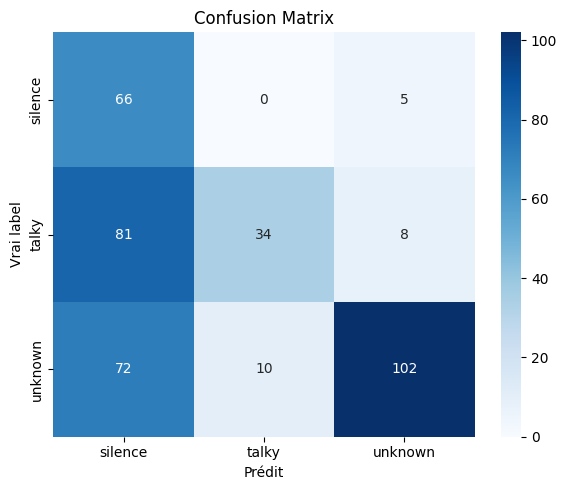

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Prédictions sur le test set (Jonas)
y_pred = np.argmax(model.predict(test_ds), axis=1)
y_true = np.concatenate([y for _, y in test_ds], axis=0)

# Classification report
print(classification_report(y_true, y_pred, target_names=CLASSES))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.title("Confusion Matrix")
plt.ylabel("Vrai label")
plt.xlabel("Prédit")
plt.tight_layout()
plt.savefig("confusion_matrix_jonas.png", dpi=150)
plt.show()

## Tester les moments de convergence

In [81]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])

In [82]:
best_epoch = np.argmax(history.history["val_accuracy"]) + 1
best_val_acc = np.max(history.history["val_accuracy"])

print(f"Best Epoch : {best_epoch}")
print(f"Val Acc : {best_val_acc})")

Best Epoch : 25
Val Acc : 0.7368420958518982)


## Tracer Val accuracy

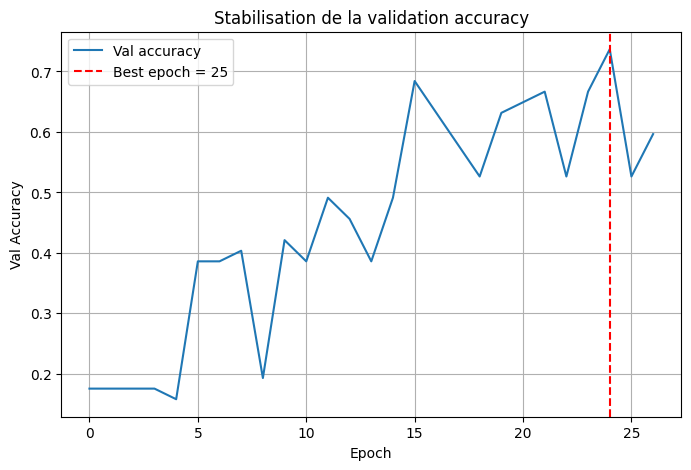

Best val acc: 0.7368420958518982


In [83]:
import numpy as np
import matplotlib.pyplot as plt

val_acc = history.history["val_accuracy"]
best_epoch = np.argmax(val_acc)

plt.figure(figsize=(8,5))

plt.plot(val_acc, label="Val accuracy")
plt.axvline(best_epoch, color="red", linestyle="--", label=f"Best epoch = {best_epoch+1}")

plt.xlabel("Epoch")
plt.ylabel("Val Accuracy")
plt.title("Stabilisation de la validation accuracy")
plt.legend()
plt.grid(True)

plt.show()

print("Best val acc:", val_acc[best_epoch])


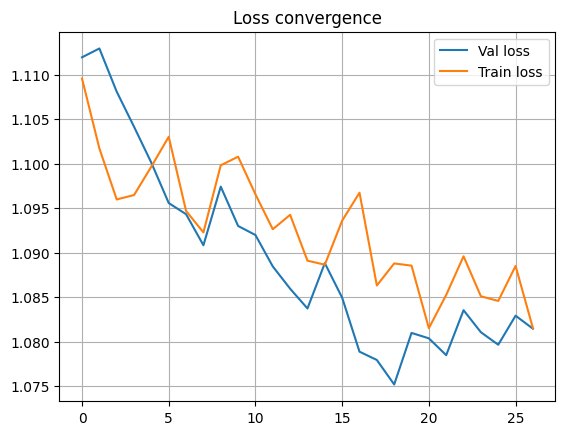

In [84]:
plt.plot(history.history["val_loss"], label="Val loss")
plt.plot(history.history["loss"], label="Train loss")
plt.legend()
plt.grid()
plt.title("Loss convergence")
plt.show()